In [2]:
import matplotlib.pyplot as plt
import numpy as np

In [3]:
def compute_eit_rates(Delta_c, kappa_as=1.0, Omega_c=2.0, g_as=0.3, delta_e=0.0, delta_g=0.0):
    """calculates c_1, c_2 and the effective rate c_1 + 2*c_2.

    Parameters:
    -----------
    Delta_c  : float or np.ndarray
        laser-detuning (Detuning)
    kappa_as : float
        decay rate / cavity losses of anti-Stokes mode
    Omega_c  : float
        Rabi-frequency of control laser
    g_as     : float
        coupling strength of anti-Stokes transition to cavity
    delta_e  : float
        Stark-shift of state |e>
    delta_g  : float
        Stark-shift of state |g>
    """
    # |A|^2
    A_sq = kappa_as**2 + 4 * (Delta_c - delta_g) ** 2

    # real- and imaginary part X, Y of (A*B + Omega_c^2)
    X = (
        kappa_as**2
        - 4 * (Delta_c - delta_g) * (delta_e - delta_g)
        + Omega_c**2
    )
    Y = 2 * kappa_as * (Delta_c + delta_e - 2 * delta_g)

    # denominator |D|^2
    term1 = (Delta_c - delta_e) * X + 4 * (Delta_c - delta_g) * g_as**2
    term2 = (Delta_c - delta_e) * Y - 2 * kappa_as * g_as**2
    Den = term1**2 + term2**2

    # prefactor
    prefactor = Omega_c**2 * g_as**2 * kappa_as

    # c_1 and c_2
    c1 = prefactor * (A_sq + Omega_c**2) / Den
    c2 = (
        4
        * prefactor
        * ((Delta_c - delta_g) ** 2 - (delta_e - delta_g) ** 2 - g_as**2)
        / Den
    )

    Gamma_eff = c1 + 2 * c2

    return c1, c2, Gamma_eff


# -----------------------------------------------------------------------------
# parameter-configuration
# -----------------------------------------------------------------------------
kappa_as = 10.0  # reference
Omega_c = 2.0  # control laser-coupling
g_as = 0.4  # anti-Stokes coupling
delta_e = 0.5  # Stark-shift of state |e>
delta_g = 0.0  # Stark-shift of state |g>

# detuning-range Delta_c
Delta_c = np.linspace(-8.0, 8.0, 1000)

# calculate rates
c1, c2, Gamma_eff = compute_eit_rates(
    Delta_c,
    kappa_as=kappa_as,
    Omega_c=Omega_c,
    g_as=g_as,
    delta_e=delta_e,
    delta_g=delta_g,
)


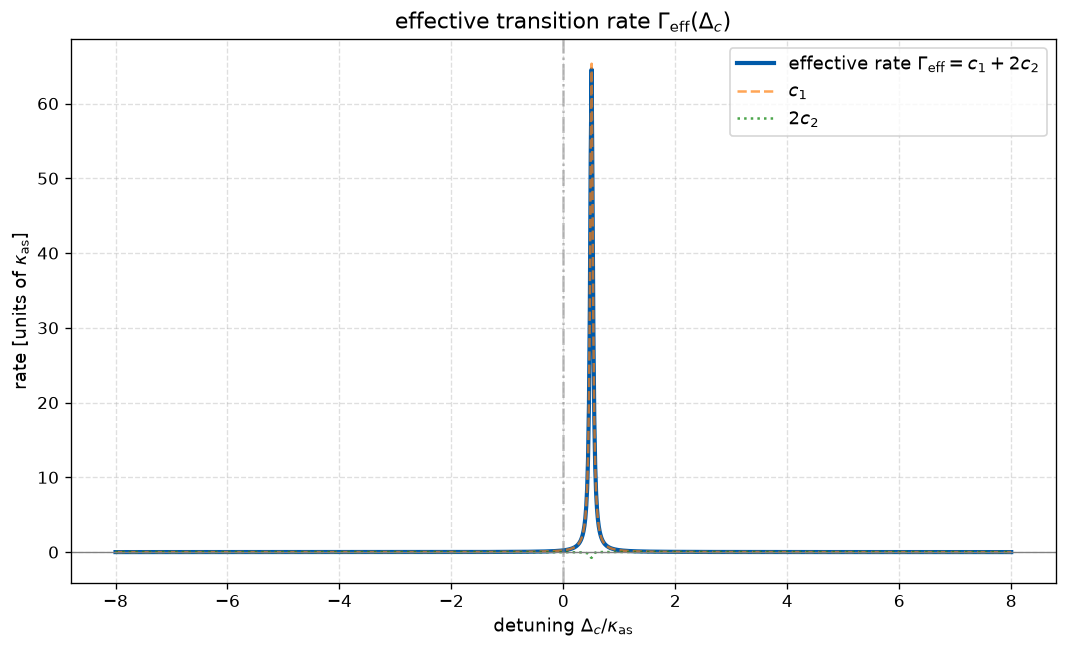

In [41]:
# -----------------------------------------------------------------------------
# plot
# -----------------------------------------------------------------------------
plt.figure(figsize=(9, 5.5), dpi=120)

plt.plot(
    Delta_c,
    Gamma_eff,
    label=r"effective rate $\Gamma_{\mathrm{eff}} = c_1 + 2c_2$",
    color="#005AA9",  # TuDa Blau
    lw=2.5,
)
plt.plot(
    Delta_c,
    c1,
    label=r"$c_1$",
    color="#ff7f0e",
    linestyle="--",
    alpha=0.7,
    lw=1.5,
)
plt.plot(
    Delta_c,
    2 * c2,
    label=r"$2c_2$",
    color="#008000",
    linestyle=":",
    alpha=0.7,
    lw=1.5,
)

plt.axvline(0, color="gray", linestyle="-.", alpha=0.5)
plt.axhline(0, color="gray", lw=0.8)

plt.title(
    r"effective transition rate $\Gamma_{\mathrm{eff}}(\Delta_c)$",
    fontsize=13,
)
plt.xlabel(r"detuning $\Delta_c / \kappa_{\mathrm{as}}$", fontsize=11)
plt.ylabel(r"rate [units of $\kappa_{\mathrm{as}}$]", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend(fontsize=11, loc="upper right")

plt.tight_layout()
plt.show()


# Actually, \Gamma_eff is not \Gamma_as. \Gamma_as is only c_1

In [4]:
def compare_rate_to_approximation(Delta_c, kappa_as=1.0, Omega_c=2.0, g_as=0.3, delta_e=0.0, delta_g=0.0):
    # |A|^2
    A_square = kappa_as **2 + 4 * (Delta_c - delta_g) ** 2
    
    # X und Y
    X = kappa_as ** 2 - 4 * (Delta_c - delta_g) * (delta_e - delta_g) + Omega_c ** 2
    Y = 2 * kappa_as * (Delta_c + delta_e - 2 * delta_g)
    
    # nominator 
    nom_c1 = Omega_c ** 2 * g_as ** 2 * kappa_as * (A_square + Omega_c ** 2)
    nom_c2 = 4 * Omega_c ** 2 * g_as ** 2 * kappa_as * ((Delta_c - delta_g) ** 2 - (delta_e - delta_g) ** 2 - g_as ** 2)
    
    # denominator split into two terms
    term1 = ((Delta_c - delta_e) * X + 4 * (Delta_c - delta_g) * g_as ** 2) ** 2
    term2 = ((Delta_c - delta_e) * Y - 2 * kappa_as * g_as ** 2) ** 2
    denom = term1 + term2
    
    # coefficients
    c1 = nom_c1 / denom
    c2 = nom_c2 / denom
    
    # exact Gamma_as
    Gamma_as = c1 + 2 * c2
    
    # approximate Gamma_as
    Gamma_as_approx = c1
    
    return Gamma_as, Gamma_as_approx
    
# Delta_c_span = np.linspace(-5, 5, 500)
# Gamma_as = []
# Gamma_as_approx = []    
    
# kappa_as = 10
# Omega_c = 0.03
# g_as = 1
# Delta_p = 20
# Omega_p = 3
# g_s = 1

# delta_g = Omega_p ** 2 / (4 * Delta_p)
# delta_e = g_as ** 2 / Delta_p

# # for Delta in Delta_c_span:
# #     exact, approx = compare_rate_to_approximation(Delta, kappa_as=kappa_as, Omega_c=Omega_c, g_as=g_as, delta_e=(g_as ** 2 / Delta_c), delta_g=delta_g)
    
# #     Gamma_as.append(exact)
# #     Gamma_as_approx.append(approx)
    
# Gamma_as, Gamma_as_approx = compare_rate_to_approximation(Delta_c_span, kappa_as=kappa_as, Omega_c=Omega_c, g_as=g_as, delta_e=delta_e, delta_g=delta_g)

0.0020703577238885846
0.0022502527596779103


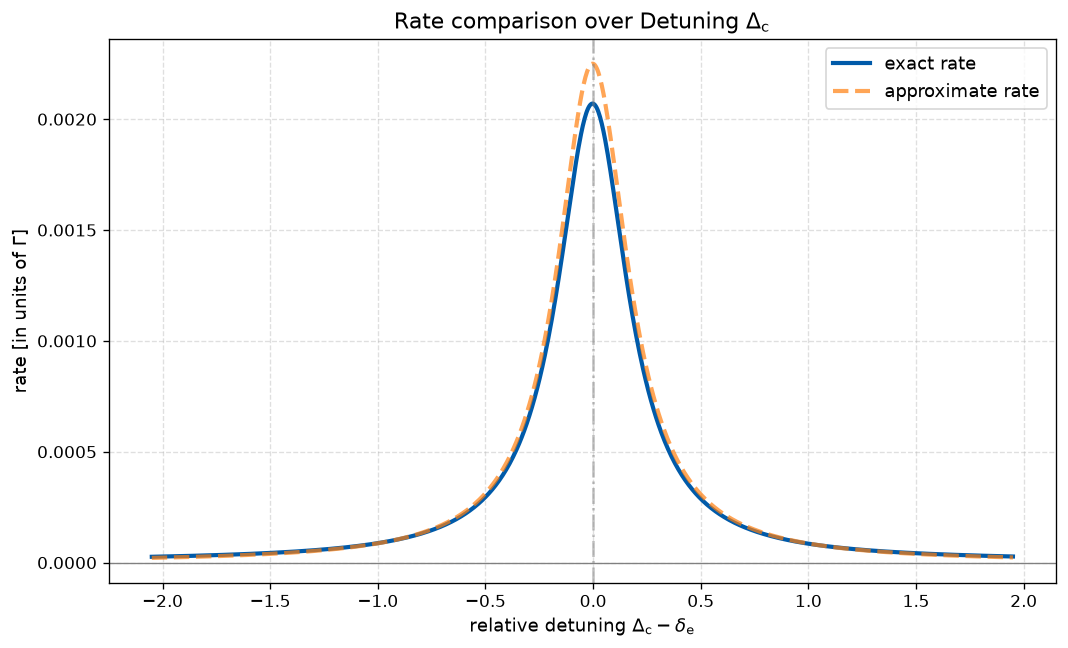

In [5]:
import matplotlib.pyplot as plt
import numpy as np

# Delta_c_span ohne exakte Null definieren, um Division durch Null zu vermeiden
Delta_c_span = np.linspace(-2, 2, 1000)
Delta_c_span = Delta_c_span[Delta_c_span != 0]

kappa_as = 10
Omega_c = 0.03
g_as = 1
g_s = 1
Delta_p = 20
Omega_p = 3

delta_g = Omega_p**2 / (4 * Delta_p)
delta_e = g_s**2 / Delta_p

Gamma_as, Gamma_as_approx = compare_rate_to_approximation(
    Delta_c_span,
    kappa_as=kappa_as,
    Omega_c=Omega_c,
    g_as=g_as,
    delta_e=delta_e,
    delta_g=delta_g,
)

plt.figure(figsize=(9, 5.5), dpi=120)

plt.plot(
    Delta_c_span - delta_e,
    Gamma_as,
    label=r"exact rate",
    color="#005AA9",  # TuDa Blau
    lw=2.5,
)
plt.plot(
    Delta_c_span - delta_e,
    Gamma_as_approx,
    label=r"approximate rate",
    color='#ff7f0e',
    linestyle="--",
    alpha=0.7,
    lw=2.5,
)

plt.axvline(0, color="gray", linestyle="-.", alpha=0.5)
plt.axhline(0, color="gray", lw=0.8)

plt.title(
    r"Rate comparison over Detuning $\Delta_\mathrm{c}$",
    fontsize=13,
)
plt.xlabel(r"relative detuning $\Delta_\mathrm{c} - \delta_\text{e}$", fontsize=11)
plt.ylabel(r"rate [in units of $\Gamma$]", fontsize=11)
# plt.xlim([-5, 5])
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend(fontsize=11, loc="upper right")

print(max(Gamma_as))
print(max(Gamma_as_approx))

plt.tight_layout()
plt.show()

In [10]:
# try to plot the Bloch equation rho_ag under the assumption of equal population of e and g, nearly no population in a

def get_rho_ag(Delta_c, Gamma_s, kappa_as, Omega_c, g_as, g_s, Omega_p, Delta_p):

    delta_g = Omega_p**2 / (4*Delta_p)
    delta_e = g_s**2 / Delta_p

    A = (Gamma_s + kappa_as) + 2 * 1j * (Delta_c - delta_g)
    B = (Gamma_s + kappa_as) + 2 * 1j * (delta_e - delta_g)

    term1 =  Omega_c**2 * g_as / ((Delta_c - delta_e) * (A * B + Omega_c**2) + 2j * A * g_as**2)
    term2 = 2j  * g_as * (B * (Delta_c - delta_e) + 2j * g_as**2) / ((A * B + Omega_c**2) * (Delta_c - delta_e) + 2j * A * g_as**2)
    
    rho_ag = -term1 * 1/2 - term2 * 1/2
    
    # rho_ag = term1 * 1 + term2 * 0
    
    return rho_ag

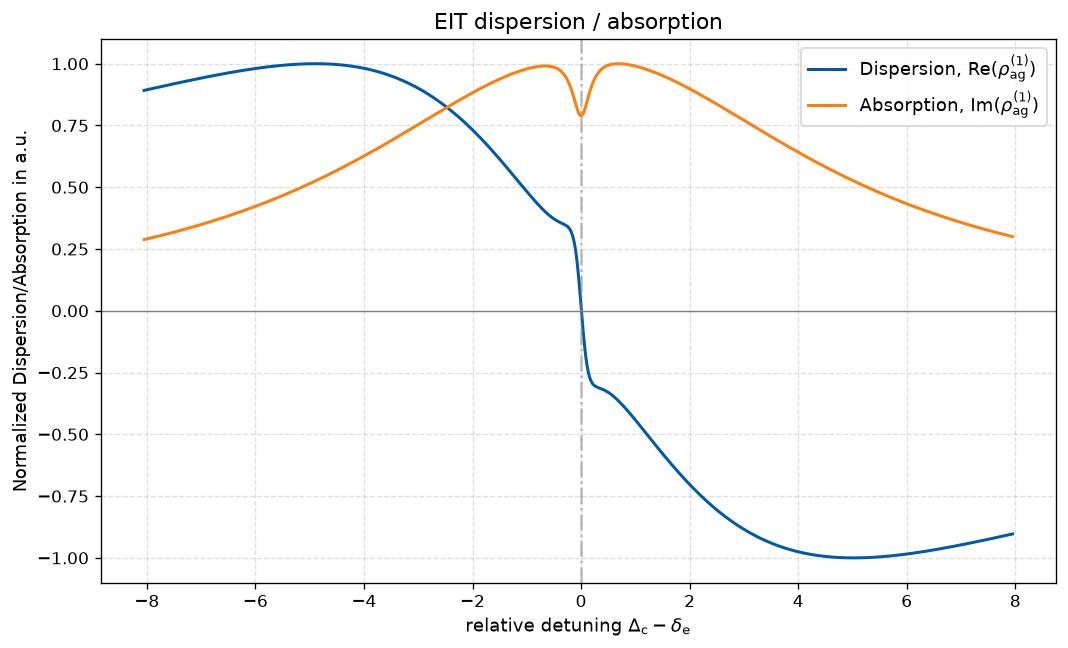

In [12]:
# Delta_c_span ohne exakte Null definieren, um Division durch Null zu vermeiden
Delta_c_span = np.linspace(-8, 8, 1000)

kappa_s = 10
kappa_as = 10
Omega_c = 1
g_as = 1
g_s = 1
Delta_p = 20
Omega_p = 3

delta_g = Omega_p**2 / (4 * Delta_p)
delta_e = g_s**2 / Delta_p

Gamma_s = g_s**2 * Omega_p**2 / (kappa_s * Delta_p**2)

rho_ag = get_rho_ag(
    Delta_c_span, 
    Gamma_s = Gamma_s,
    kappa_as=kappa_as, 
    Omega_c=Omega_c, 
    g_as=g_as, 
    g_s=g_s, 
    Omega_p=Omega_p, 
    Delta_p=Delta_p)

# suppose N=\varepsilon_0=\mu_13=1 (formula from proposals)
chi = rho_ag / Omega_p

real_part = chi.real
imag_part = chi.imag

real_norm = real_part / np.max(np.abs(real_part))
imag_norm = imag_part / np.max(np.abs(imag_part))

plt.figure(figsize=(9, 5.5), dpi=120)

plt.plot(
    Delta_c_span - delta_e,
    real_norm,
    label=r"Dispersion, Re($\rho_\text{ag}^{(1)}$)",
    color="#005AA9",
    lw=1.8,
)

plt.plot(
    Delta_c_span - delta_e,
    -imag_norm,
    label=r"Absorption, Im($\rho_\text{ag}^{(1)}$)",
    color="#ff7f0e",
    lw=1.8,
)

plt.axvline(0, color="gray", linestyle="-.", alpha=0.5)
plt.axhline(0, color="gray", lw=0.8)

plt.title(
    r"EIT dispersion / absorption",
    fontsize=13,
)
plt.xlabel(r"relative detuning $\Delta_\text{c} - \delta_\text{e}$", fontsize=11)
plt.ylabel(r"Normalized Dispersion/Absorption in a.u.", fontsize=11)
# plt.xlim([-5, 5])
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend(fontsize=11, loc="upper right")

plt.tight_layout()
plt.savefig("C:/Users/lauri/OneDrive/Desktop/Uni/Physik/Master/Thesis/Code/Results/EIT_window_with_incoherent_pump.pdf")
plt.show()


max exact $Gamma_\text{as}$: 2.525762170067889
max approximate $Gamma_\text{as}$: 2.4999998434370405
difference in maximum value: 0.02576232663084843


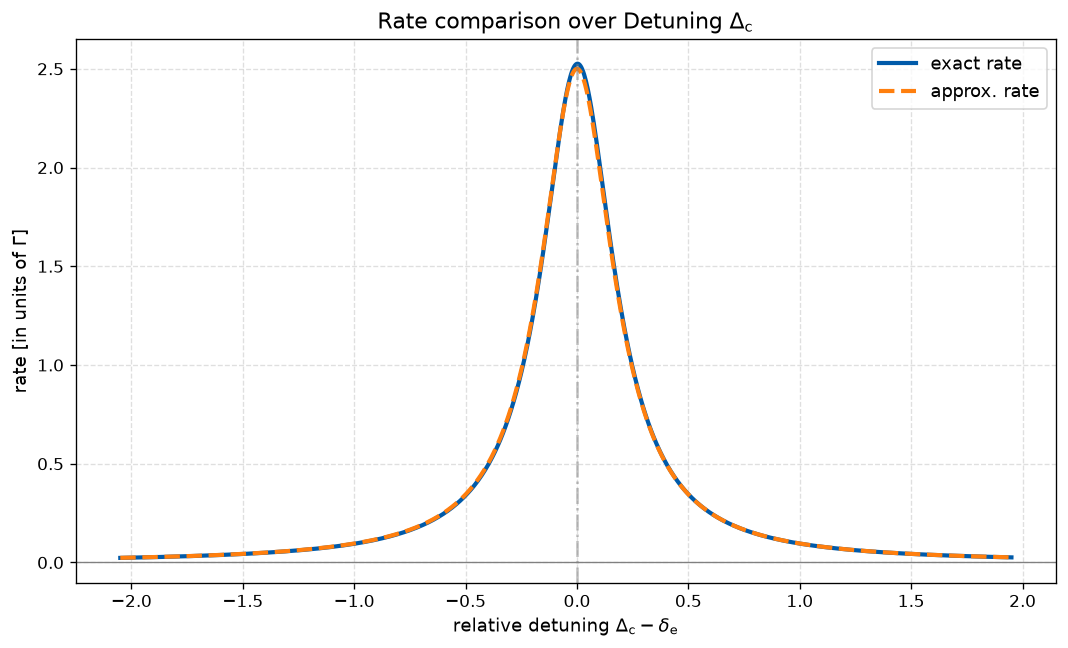

In [19]:
# let's check if the approximation up to second order gives an approximate rate

def calculate_gammas(Omega_p, Omega_c, Delta_p, Delta_c, kappa_s, kappa_as, g_s, g_as):
    
    Gamma_s = g_s**2 * Omega_p**2 / (kappa_s * Delta_p**2)
    
    delta_g = Omega_p**2 / (4 * Delta_p)
    delta_e = g_s**2 / Delta_p
    
    # first calculate the exact Gamma_as
    
    A_square = (Gamma_s + kappa_as)**2 + 4 * (Delta_c - delta_g)**2
    
    X = (Gamma_s + kappa_as)**2 + Omega_c**2 - 4 * (Delta_c - delta_g) * (delta_e - delta_g)
    Y = 2 * (Gamma_s + kappa_as) * (Delta_c + delta_e - 2 * delta_g)
    
    nom_exact = Omega_c**2 * g_as**2 * (Gamma_s + kappa_as) * (A_square + Omega_c**2)
    denom_exact = ((Delta_c - delta_e)* X - 4 * (Delta_c - delta_g) * g_as**2)**2 + ((Delta_c - delta_e) * Y + 2 * (Gamma_s + kappa_as) * g_as**2)**2
    
    Gamma_as = nom_exact / denom_exact
    
    # then calculate the approimate rate up to order 3
    
    nom_approx = Omega_c**2 * g_as**2 * kappa_as
    denom_approx = (Delta_c - delta_e)**2 * kappa_as**2 + 4 * g_as**4
    
    Gamma_as_approx = nom_approx / denom_approx
    
    return Gamma_as, Gamma_as_approx
    
    
    
kappa_s = 10
kappa_as = 10
Omega_c = 1
g_as = 1
g_s = 1
Delta_p = 20
Omega_p = 3

Delta_c_span = np.linspace(-2, 2, 1000)

Gamma_as, Gamma_as_approx = calculate_gammas(Omega_p=Omega_p, Omega_c=Omega_c, Delta_p=Delta_p, Delta_c=Delta_c_span, kappa_s=kappa_s, kappa_as=kappa_as, g_s=g_s, g_as=g_as)

print(rf"max exact $Gamma_\text{{as}}$: {max(Gamma_as)}")
print(rf"max approximate $Gamma_\text{{as}}$: {max(Gamma_as_approx)}")
print(f"difference in maximum value: {max(Gamma_as) - max(Gamma_as_approx)}")

delta_e = g_s**2/Delta_p

plt.figure(figsize=(9, 5.5), dpi=120)

plt.plot(
    Delta_c_span - delta_e,
    Gamma_as,
    label=r"exact rate",
    color="#005AA9", 
    lw=2.5,
)
plt.plot(
    Delta_c_span - delta_e,
    Gamma_as_approx,
    label=r"approx. rate",
    color="#ff7f0e", 
    lw=2.5,
    linestyle="--"
)

plt.axvline(0, color="gray", linestyle="-.", alpha=0.5)
plt.axhline(0, color="gray", lw=0.8)

plt.title(
    r"Rate comparison over Detuning $\Delta_\mathrm{c}$",
    fontsize=13,
)
plt.xlabel(r"relative detuning $\Delta_\mathrm{c} - \delta_\text{e}$", fontsize=11)
plt.ylabel(r"rate [in units of $\Gamma$]", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend(fontsize=11, loc="upper right")

plt.tight_layout()
plt.show()

max exact $Gamma_\text{as}^{1}$: 0.0942320371671019


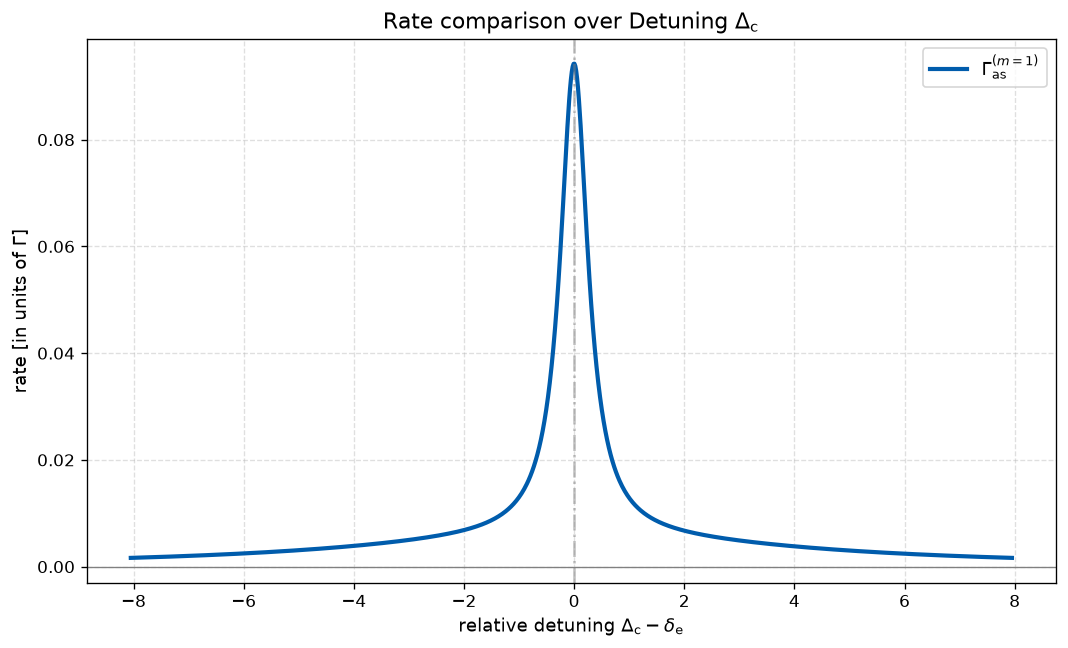

In [7]:
# let's check if the approximation up to second order gives an approximate rate


def calculate_gamma_two_atoms(Omega_p, Omega_c, Delta_p, Delta_c, kappa_as, g_s, g_as):
    delta_g = Omega_p**2 / (4 * Delta_p)
    delta_e = g_s**2 / Delta_p

    A_square = kappa_as**2 + 4 * (Delta_c - delta_g)**2

    nom_c2 = np.sqrt(2) * kappa_as * Omega_c * (4 * g_as**4 + 4 * g_as**2 * (Delta_c - delta_e)**2 + 2 * g_as**2 * Omega_c**2)
    nom_c3 = np.sqrt(2) * kappa_as * Omega_c * (-(Delta_c - delta_e)**2 * A_square + 4 * (Delta_c - delta_e) * (Delta_c - delta_g) * Omega_c**2 - Omega_c**4 - 2 * g_as**2 * Omega_c**2)
    
    denom = kappa_as**2 * (2 * g_as**2 - 2 * (Delta_c - delta_e)**2 + Omega_c**2)**2 + (4 * g_as**2 * (Delta_c - delta_g) + (Delta_c - delta_e) * (4 *(Delta_c - delta_g) * (delta_e - delta_g) + kappa_as**2) - 2 * (delta_e - delta_g) * Omega_c**2)**2
    
    Gamma_as = nom_c2 / denom

    return Gamma_as

    
    
kappa_s = 10
kappa_as = 10
Omega_c = 1
g_as = 1
g_s = 1
Delta_p = 20
Omega_p = 0

Delta_c_span = np.linspace(-8, 8, 1000)

Gamma_as = calculate_gamma_two_atoms(Omega_p=Omega_p, Omega_c=Omega_c, Delta_p=Delta_p, Delta_c=Delta_c_span, kappa_as=kappa_as, g_s=g_s, g_as=g_as)

print(rf"max exact $Gamma_\text{{as}}^{{1}}$: {max(Gamma_as)}")

delta_e = g_s**2/Delta_p

plt.figure(figsize=(9, 5.5), dpi=120)

plt.plot(
    Delta_c_span - delta_e,
    Gamma_as,
    label=r"$\Gamma_\text{{as}}^{{(m=1)}}$",
    color="#005CAC", 
    lw=2.5,
)
# plt.plot(
#     Delta_c_span - delta_e,
#     Gamma_as_2,
#     label=r"$\Gamma_\text{{as}}^{{(m=2)}}$",
#     color="#FF7300DD", 
#     lw=2.5,
# )

plt.axvline(0, color="gray", linestyle="-.", alpha=0.5)
plt.axhline(0, color="gray", lw=0.8)

plt.title(
    r"Rate comparison over Detuning $\Delta_\mathrm{c}$",
    fontsize=13,
)
plt.xlabel(r"relative detuning $\Delta_\mathrm{c} - \delta_\text{e}$", fontsize=11)
plt.ylabel(r"rate [in units of $\Gamma$]", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend(fontsize=11, loc="upper right")

plt.tight_layout()
plt.show()

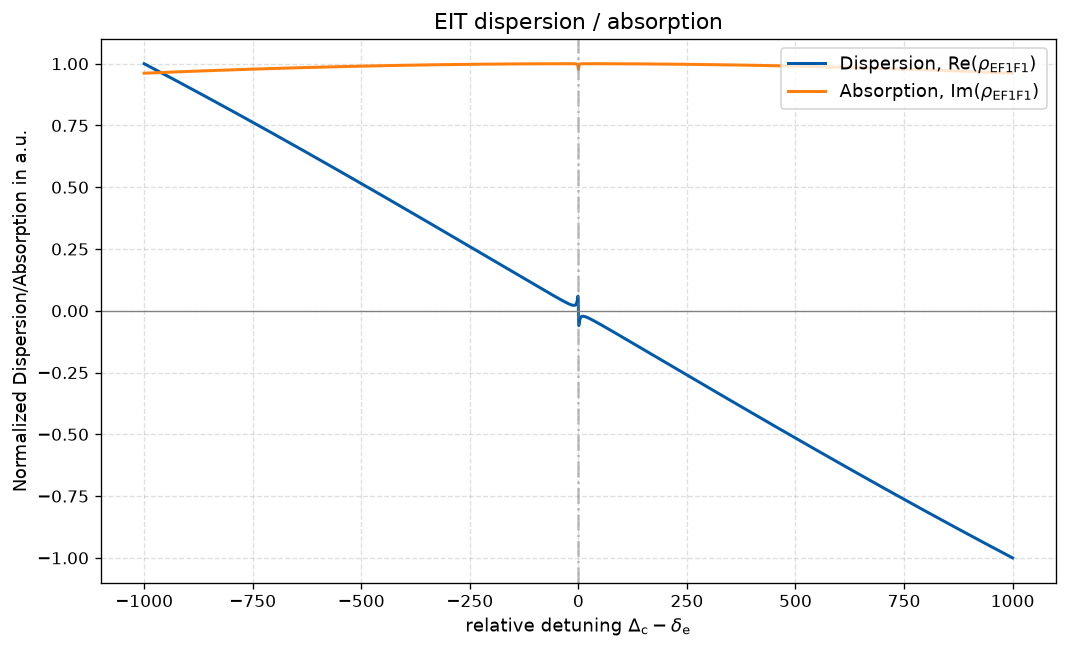

In [79]:
# Hier testen wir das Matrixelement für EIT mit N=2, ob wir ein EIT-Fenster sehen
Delta_c_span = np.linspace(-1000, 1000, 10000)

kappa_s = 10000
kappa_as = 10000
Omega_c = 0.3
g_as = 1
g_s = 1
Delta_p = 20
Omega_p = 3


delta_g = 2 * Omega_p**2 / (4 * Delta_p**2)
delta_e = g_s**2 / Delta_p


def rho_EFF(Omega_p, Omega_c, Delta_p, Delta_c, g_s, g_as, kappa_s, kappa_as):
    
    N = 10000
    m = 5000
    
    # g_as = g_as / np.sqrt(N)
    
    Gamma_s = 0 #(Omega_p**2 * g_s**2)/(kappa_s * Delta_p**2) * (N - m) * (m + 1)
    
    A = (Gamma_s + kappa_as) + 2j * (Delta_c - delta_g)
    B = (Gamma_s + kappa_as) + 2j * (delta_e - delta_g)    
    
    nom1 = 2j * np.sqrt(N - m) * g_as * (B * (Delta_c - delta_e) + 2j * (N-m) * g_as**2)
    nom2 =  (m+1) * np.sqrt(N - m) * g_as * Omega_c**2
    
    denom = (A * B + (m + 1) * Omega_c**2) * (Delta_c - delta_e) + 2j * A * (N - m) * g_as**2
    
    term1 = nom1/denom 
    term2 = nom2/denom
    
    rho_EFF = -1/2 * term1 - 1/2 * term2
    
    return rho_EFF
    
rho_EFF_val = rho_EFF(Omega_p=Omega_p, Omega_c=Omega_c, Delta_p=Delta_p, Delta_c=Delta_c_span, g_s=g_s, g_as=g_as, kappa_s=kappa_s, kappa_as=kappa_as)

# suppose N=\varepsilon_0=\mu_13=1 (formula from proposals)
chi = rho_EFF_val / Omega_p

real_part = chi.real
imag_part = chi.imag

real_norm = real_part / np.max(np.abs(real_part))
imag_norm = imag_part / np.max(np.abs(imag_part))

plt.figure(figsize=(9, 5.5), dpi=120)

plt.plot(
    Delta_c_span - delta_e,
    real_norm,
    label=r"Dispersion, Re($\rho_\text{EF1F1}$)",
    color="#005AA9",
    lw=1.8,
)

plt.plot(
    Delta_c_span - delta_e,
    -imag_norm,
    label=r"Absorption, Im($\rho_\text{EF1F1}$)",
    color="#ff7f0e",
    lw=1.8,
)

plt.axvline(0, color="gray", linestyle="-.", alpha=0.5)
plt.axhline(0, color="gray", lw=0.8)

plt.title(
    r"EIT dispersion / absorption",
    fontsize=13,
)
plt.xlabel(r"relative detuning $\Delta_\text{c} - \delta_\text{e}$", fontsize=11)
plt.ylabel(r"Normalized Dispersion/Absorption in a.u.", fontsize=11)
# plt.xlim([-0.25, 0.25])
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend(fontsize=11, loc="upper right")

plt.tight_layout()
plt.savefig("C:/Users/lauri/OneDrive/Desktop/Uni/Physik/Master/Thesis/Code/Results/EIT_window_with_incoherent_pump_N_2.pdf")
plt.show()


In [25]:
Delta_c_span_neg = np.linspace(-2, 0, 1000)
Delta_c_span_pos = np.linspace(0, 2, 1000)

kappa_s = 10
kappa_as = 10
Omega_c = 0.5
g_as = 1
g_s = 1
Delta_p = 20
Omega_p = 3


delta_g = 2 * Omega_p**2 / (4 * Delta_p**2)
delta_e = g_s**2 / Delta_p

rho_EF1F1_neg = rho_EF1F1(Omega_p=Omega_p, Omega_c=Omega_c, Delta_p=Delta_p, Delta_c=Delta_c_span_neg, g_s=g_s, g_as=g_as, kappa_s=kappa_s, kappa_as=kappa_as)
rho_EF1F1_pos = rho_EF1F1(Omega_p=Omega_p, Omega_c=Omega_c, Delta_p=Delta_p, Delta_c=Delta_c_span_pos, g_s=g_s, g_as=g_as, kappa_s=kappa_s, kappa_as=kappa_as)

print(f"Maximum absorption in negative detuning range: {max(rho_EF1F1_neg.imag)}")
print(f"Maximum absorption in positive detuning range: {max(rho_EF1F1_pos.imag)}")

Maximum absorption in negative detuning range: -0.08474427322848975
Maximum absorption in positive detuning range: -0.08496763339502292
